# PartB - World map of glacier model differences

One subplot per RGI region (and Global). The figure should answer one question: **how much do the glacier models differ?** Two versions:
- `y80`: **left** mass after 80 simulation years, **right** steady-state mass (both mass remaining in % of 2020, one shared y-axis)
- `tau`: **left** steady-state mass, **right** response timescale (80% of the total change, not shifted to 2020)

Two subplot styles:
- `range` (default): per plot one bar = range of the four global models, a black line = their median, and the number = median glacier model difference
- `dots`: all models as dots (four global models as circles, regional models as diamonds)

In [3]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Rectangle
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature

In [4]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42  # keep the text editable in the pdf

## Settings

In [10]:
# which versions of the figure and which values?
variants = ['y80', 'tau']     # 'y80': 80 years | steady state,  'tau': steady state | response timescale
modes = ['abs', 'diff']       # 'abs': absolute values,  'diff': difference to the median of the four global models
subplot_style = 'range'         # 'range': bar (range of the four global models), 'dots': all models as dots

# data (change to your local paths), created in PartB_3 and PartB_2
fn_steady_state = 'PartB_data/steady_state_relative_volume_change.csv'
fn_after80 = 'PartB_data/after80yrs_relative_volume_change.csv'
fn_resp_time = 'PartB_data/resp_time_non_shifted_for_deltaT_rgi_reg_roll_volume_area_21yravg.csv'

temp_bin = [2.0, 4.0]         # global warming bin in °C
n_scen = 31                   # number of climate scenarios in this bin (checked in the data below)
show_numbers = True           # 'Alaska (01)' or just 'Alaska'

add_rgi_regions = True       # outlines of the RGI regions, see Attention below
add_rgi_glaciers = True      # grey dots for all RGI glaciers, see Attention below

fig_dir = 'figures_partB/worldmap_fig1/'
os.makedirs(fig_dir, exist_ok=True)

**Attention:** to add the RGI region outlines and the glacier dots as in the GMIP3-comm worldmap (`4_world_map_figure...ipynb`), you need `rgi60_regions_robinson-v2.shp` from `GlacierMIP3/data/data_from_others` and the RGI stats file. Set `add_rgi_regions` and `add_rgi_glaciers` to True and adapt the paths:

In [7]:
rgi_regions_fn = '../data/data_from_others/rgi60_regions_robinson-v2.shp'
# only needed if add_rgi_glaciers = True (as in the GMIP3-comm notebook: df_rgi6g with 'CenLon', 'CenLat')
if add_rgi_glaciers:
    from oggm import utils
    df_rgi6g = pd.read_hdf(utils.file_downloader('https://cluster.klima.uni-bremen.de/~oggm/rgi/rgi62_stats.h5'))
    df_rgi6g = df_rgi6g.loc[df_rgi6g.Connect != 2]

## Names, colours and positions

In [11]:
# names of the RGI regions (could also be taken from d_reg_num_name in help_functions)
reg_names = {'All': 'Global', '01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
             '05': 'Greenland Periphery', '06': 'Iceland', '07': 'Svalbard & Jan Mayen', '08': 'Scandinavia',
             '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus & Middle East',
             '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
             '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic & Antarctic Islands'}

# names with a line break where a name is long (the number is added in the title of the subplot)
reg_names_lines = dict(reg_names)
reg_names_lines.update({'05': 'Greenland\nPeriphery', '07': 'Svalbard &\nJan Mayen',
                        '12': 'Caucasus &\nMiddle East',
                        '19': 'Subantarctic &\nAntarctic Islands'})

# glacier models: the four global models are in the median, the regional models are only shown (style 'dots')
global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_csv = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the csv files, all others are the same

# colours as in the model difference figures (could be replaced by pal_models from help_functions)
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}
col_80, col_ss, col_tau = '#2a7f7f', '#3b4a6b', '#b5532a'

# position of the subplots (centre, in figure fractions) and the point where the line to the region ends (lon, lat)
# TODO: the lon/lat points are only approximate, could be replaced by the centres of the RGI regions
subplot_pos = {'01': [0.105, 0.835], '02': [0.105, 0.610], '03': [0.270, 0.905], '04': [0.285, 0.690], '05': [0.380, 0.905],
             '06': [0.440, 0.715], '07': [0.500, 0.905], '08': [0.570, 0.735], '09': [0.660, 0.905], '10': [0.905, 0.800],
             '11': [0.525, 0.585], '12': [0.606, 0.550], '13': [0.785, 0.745], '14': [0.692, 0.500], '15': [0.775, 0.550],
             '16': [0.275, 0.480], '17': [0.300, 0.215], '18': [0.915, 0.360], '19': [0.500, 0.200]}
reg_lonlat = {'01': [-145, 62], '02': [-121, 52], '03': [-80, 80], '04': [-70, 68], '05': [-40, 70], '06': [-18, 64.8],
              '07': [16, 78], '08': [16, 67.5], '09': [70, 75], '10': [150, 60], '11': [10, 46.5], '12': [44, 43],
              '13': [80, 42], '14': [74, 35.5], '15': [90, 29], '16': [-75, -5], '17': [-72, -45], '18': [170.5, -43.5],
              '19': [-37, -54.5]}

## 1. Prepare the data

Everything is computed from the raw columns of the csv files for the temperature bin 2.0°C to 4.0°C (31 climate scenarios), with the **median of the four global models** as reference ((two steps: median over the four models for each scenario, then median over the 31 scenarios; only the delta number pools all 124 values):
- reference: median over the four global models, for every climate scenario
- bar / dot: median over the climate scenarios of the model value (absolute) or of the difference to the reference (difference)
- black line: median over the 31 climate scenarios of the reference
- number: median of all |model - reference| of the four global models and all climate scenarios (regional models are not included; 4 global models × 31 scenarios = 124 values")
- response timescale: no estimate if more than 25% of the experiments are missing for one of the four global models (as in PartB_2)

In [12]:
pd_ss = pd.read_csv(fn_steady_state, index_col=0)
pd_80 = pd.read_csv(fn_after80, index_col=0)
pd_rt = pd.read_csv(fn_resp_time, index_col=0)

# same names for models and regions everywhere
for pd_x in [pd_ss, pd_80]:
    pd_x['model'] = pd_x.model_author.replace(model_names_csv)
    pd_x['reg'] = pd_x.rgi_reg.replace({'Global': 'All'})

# response timescale: only volume, without OGGM-VAS (not part of the model set)
pd_rt = pd_rt.loc[(pd_rt.metric == 'volume_m3') & (pd_rt.model_author != 'OGGM-VAS')].copy()
pd_rt['model'] = pd_rt.model_author.replace(model_names_csv)
pd_rt['reg'] = pd_rt.rgi_reg.str.replace('RGI', '')

print(pd_ss.shape, pd_80.shape, pd_rt.shape)

(7680, 12) (7680, 13) (6251, 14)


In [13]:
def get_mass_table(pd_in, prefix):
    # remaining mass in % of 2020, steady state or after 80 years: one row per region
    pd_bin = pd_in.loc[(pd_in.temp_ch_ipcc >= temp_bin[0]) & (pd_in.temp_ch_ipcc <= temp_bin[1])]
    np.testing.assert_allclose(len(pd_bin.groupby(['gcm', 'period_scenario'])), n_scen)
    d = {}
    for reg, pd_reg in pd_bin.groupby('reg'):
        vals = pd_reg.pivot_table(index=['gcm', 'period_scenario'], columns='model', values='relative volume change (in %)')
        glob = vals[global_models]
        np.testing.assert_equal(glob.isna().sum().sum(), 0)
        ref = glob.median(axis=1)  # step 1: per scenario, median of the four global models (31 values)
        d[reg] = {f'{prefix}_ref': ref.median(),  # step 2: median over the 31 scenarios = black line
                  f'{prefix}_mad': np.median(np.abs(glob.sub(ref, axis=0)).values)}
        for m in vals.columns:
            d[reg][f'{prefix}_{m}'] = vals[m].median()
            d[reg][f'{prefix}d_{m}'] = (vals[m] - ref).median()
    return pd.DataFrame(d).T


def get_resp_time_table(pd_in, prefix='tau', col='resp_time_-80%'):
    # response timescale (80% of the total change, years): one row per region
    pd_bin = pd_in.loc[(pd_in.temp_ch_ipcc >= temp_bin[0]) & (pd_in.temp_ch_ipcc <= temp_bin[1])]
    n_exp = pd_bin.temp_ch_ipcc.nunique()
    np.testing.assert_allclose(n_exp, n_scen)
    d = {}
    for reg, pd_reg in pd_bin.groupby('reg'):
        vals = pd_reg.pivot_table(index='gcm_period_scenario', columns='model', values=col)
        counts = vals[global_models].count()
        if (np.abs(counts - n_exp) > 0.25 * n_exp).any():
            print(reg, 'no response timescale estimate, valid experiments per global model:', counts.to_dict())
            continue
        glob = vals[global_models].dropna()        # experiments where all four global models have a value
        ref = glob.median(axis=1)
        d[reg] = {f'{prefix}_ref': ref.median(),
                  f'{prefix}_mad': np.median(np.abs(glob.sub(ref, axis=0)).values)}
        for m in vals.columns:
            v = vals.loc[glob.index, m]
            if (m in global_models) or (v.count() >= 0.75 * len(glob)):
                d[reg][f'{prefix}_{m}'] = v.median()
                d[reg][f'{prefix}d_{m}'] = (v - ref).median()
    return pd.DataFrame(d).T

In [14]:
table_ss = get_mass_table(pd_ss, 'ss')
table_80 = get_mass_table(pd_80, 'm80')
table_tau = get_resp_time_table(pd_rt)

# one table per version of the figure
tables = {'y80': table_80.join(table_ss), 'tau': table_ss.join(table_tau)}
tables['tau'].loc[['All', '03', '08', '14', '19'], ['ss_ref', 'ss_mad', 'tau_ref', 'tau_mad']].round(1)

03 no response timescale estimate, valid experiments per global model: {'PyGEM-OGGM': 31, 'GloGEMflow': 21, 'OGGM': 30, 'GLIMB': 31}
19 no response timescale estimate, valid experiments per global model: {'PyGEM-OGGM': 31, 'GloGEMflow': 10, 'OGGM': 31, 'GLIMB': 31}


,ss_ref,ss_mad,tau_ref,tau_mad
All,27.8,7.9,248.0,93.8
03,40.0,13.9,NaN,NaN
08,0.3,0.1,60.0,12.2
14,29.3,12.5,80.0,16.0
19,33.6,10.6,NaN,NaN


**Check:** why we do not use the `delta ... to median model` columns of the csv files. TODO: remove maybe this column for the file at the end ... For the steady-state file, the column is relative to the median of *all* models in the region (not only the four global models), and the 80-year file has the same year-0 volume as the steady-state file:

In [16]:
rc = 'relative volume change (in %)'
dc = 'delta relative volume change (in %, to median model)'

pd_chk = pd_ss.copy()
pd_chk['v0'] = pd_chk.volume_m3 / (pd_chk[rc] / 100)
g = pd_chk.groupby(['rgi_reg', 'gcm', 'period_scenario'])
ref_all_models = 100 * g.volume_m3.transform('median') / g.v0.transform('median')
print('max difference to the existing delta column, median over ALL models in the region:',
      np.round(np.abs(pd_chk[rc] - ref_all_models - pd_chk[dc]).max(),2), '%-points')

key = ['rgi_reg', 'model_author', 'gcm', 'period_scenario']
pd_both = pd_80.merge(pd_ss, on=key, suffixes=('_80', '_ss'))
v0_80 = pd_both['volume_m3_80'] / (pd_both[rc + '_80'] / 100)
v0_ss = pd_both['volume_m3_ss'] / (pd_both[rc + '_ss'] / 100)
print('rows matched:', len(pd_both), 'of', len(pd_80), '| max relative difference of the year-0 volume:', (np.abs(v0_80 - v0_ss) / v0_ss).max())

max difference to the existing delta column, median over ALL models in the region: 1.33 %-points
rows matched: 7680 of 7680 | max relative difference of the year-0 volume: 6.399026996409967e-13


## 2. One subplot (one RGI region)

Same idea as `reg_pie_subplot` in the GMIP3-comm worldmap notebook: function that draws one region into a given axes. The two plots of a subplot have their own y-axis (mass in %, response timescale in years), except for `y80` where both are mass in % and share one axis.

In [17]:
def reg_subplot(reg='All', ax=None, variant='y80', mode='abs', title=None, big=False, style=None):
    if style is None:
        style = subplot_style
    row = tables[variant].loc[reg]
    if big:   # the Global subplot in the legend box is larger
        fs_small, fs_num, fs_head, fs_title, fs_lab, ms, lw_med, bar_w = 6.0, 9.5, 7.8, 10.5, 6.0, 7.5, 4.2, 0.075
    else:
        fs_small, fs_num, fs_head, fs_title, fs_lab, ms, lw_med, bar_w = 4.8, 7.2, 5.0, 5.7, 5.0, 3.9, 2.8, 0.09

    # ranges and ticks of the y-axes
    if mode == 'abs':
        m_rng, m_ticks, t_rng, t_ticks = (0, 100), (0, 50, 100), (0, 400), (0, 200, 400)
        lab_m, lab_tau = 'mass, % of 2020', 'years (80% of change)'
    else:
        m_rng, m_ticks, t_rng, t_ticks = (-50, 50), (-50, 0, 50), (-300, 300), (-300, 0, 300)
        lab_m, lab_tau = 'minus median, % points', 'minus median, years'

    # the two plots: column prefix in the table, position of the axis, of the first model slot and width of a slot
    if variant == 'y80':
        panels = [dict(pre='m80', xa=0.15, xs0=0.23, dx=0.0565, rng=m_rng, ticks=m_ticks, unit='%', col=col_80,
                       head='After 80\nyears', head_big='After 80 years', lab=lab_m, axis=True),
                  dict(pre='ss', xa=None, xs0=0.625, dx=0.0565, rng=m_rng, ticks=m_ticks, unit='%', col=col_ss,
                       head='Steady\nstate', head_big='Steady state', lab=lab_m, axis=False)]
    else:
        panels = [dict(pre='ss', xa=0.15, xs0=0.23, dx=0.052, rng=m_rng, ticks=m_ticks, unit='%', col=col_ss,
                       head='Steady\nstate', head_big='Steady state', lab=lab_m, axis=True),
                  dict(pre='tau', xa=0.615, xs0=0.68, dx=0.048, rng=t_rng, ticks=t_ticks, unit='yr', col=col_tau,
                       head='Response\ntimescale', head_big='Response timescale', lab=lab_tau, axis=True)]

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color('#c4c4c4')
        sp.set_linewidth(1.6)
    if style == 'range':     # the number is on top of the bar
        y0, y1, y_num = 0.10, 0.55, (0.655 if big else 0.645)
    else:                    # the number is below the dots
        y0, y1, y_num = 0.22, 0.64, 0.09

    def y_of(v, rng):
        return y0 + (y1 - y0) * (np.clip(v, rng[0], rng[1]) - rng[0]) / (rng[1] - rng[0])

    # region name inside the subplot
    if title is not None:
        ax.text(0.5, 0.925, title, fontsize=fs_title, weight='bold', ha='center', va='center', linespacing=0.95)
        ax.plot([0.03, 0.97], [0.855, 0.855], color='#c4c4c4', lw=0.8)

    # one y-axis for both plots if both are mass in %: guide lines and a line between the plots
    if variant == 'y80':
        for t in m_ticks:
            ax.plot([0.15, 0.95], [y_of(t, m_rng)] * 2, color='0.88', lw=0.5, zorder=0)
        ax.plot([0.575, 0.575], [y0 - 0.02, y1 + 0.02], color='#c4c4c4', lw=0.8)

    regional = []
    if style == 'dots' and not big:
        regional = [m for m in regional_models if not pd.isna(row.get(f'ss_{m}', np.nan))]

    for i, p in enumerate(panels):
        xc = p['xs0'] + 2.5 * p['dx']            # middle of the six model slots
        if p['axis']:
            ax.plot([p['xa'], p['xa']], [y0, y1], color='0.4', lw=0.6)
            for t in p['ticks']:
                ax.plot([p['xa'] - 0.025, p['xa']], [y_of(t, p['rng'])] * 2, color='0.4', lw=0.6)
                ax.text(p['xa'] - 0.035, y_of(t, p['rng']), f'{t:g}', fontsize=fs_small, ha='right', va='center', color='0.3')
            if big:   # axis label in the large Global subplot
                lab_off = 0.10 if p['xa'] < 0.3 else 0.12     # a bit more space for the tick labels of the second axis
                ax.text(p['xa'] - lab_off, (y0 + y1) / 2, p['lab'], fontsize=fs_lab, rotation=90, ha='center', va='center')
        ax.text(xc, 0.795 if big else 0.775, p['head_big'] if big else p['head'], fontsize=fs_head, color=p['col'],
                weight='bold', ha='center', va='center', linespacing=0.9)

        ref = row.get(p['pre'] + '_ref', np.nan)
        if pd.isna(ref):      # no response timescale estimate (more than 25% of the experiments missing)
            ax.text(xc, 0.35, 'n/a', fontsize=fs_num - 0.8, ha='center', va='center', color='0.45', style='italic')
            continue
        shift = ref if mode == 'diff' else 0
        suffix = 'd_' if mode == 'diff' else '_'
        mad = row[p['pre'] + '_mad']
        mad_str = f'{mad:.1f}' if mad < 1 else f'{mad:.0f}'

        if style == 'range':
            # bar: range of the four global models, black line: their median
            vals = [row[p['pre'] + suffix + m] for m in global_models]
            y_lo, y_hi = y_of(min(vals), p['rng']), y_of(max(vals), p['rng'])
            y_hi = max(y_hi, y_lo + 0.012)
            ax.add_patch(Rectangle((xc - bar_w / 2, y_lo), bar_w, y_hi - y_lo, fc=p['col'], ec=p['col'], alpha=0.55,
                                   lw=0.6, zorder=2))
            ax.plot([xc - bar_w / 2 - 0.025, xc + bar_w / 2 + 0.025], [y_of(ref - shift, p['rng'])] * 2, color='k',
                    lw=lw_med, solid_capstyle='butt', zorder=3)
            if max(vals) > p['rng'][1]:      # outside of the axis: triangle at the end of the axis
                ax.plot([xc], [y1 + 0.035], '^', ms=2.4, color='0.25', zorder=4)
            if min(vals) < p['rng'][0]:
                ax.plot([xc], [y0 - 0.035], 'v', ms=2.4, color='0.25', zorder=4)
            ax.text(xc, y_num, f'\u0394 {mad_str} {p["unit"]}', fontsize=fs_num, weight='bold', ha='center', va='center')
        else:
            # thick line: median of the four global models (only along the four global slots)
            ax.plot([p['xs0'] - 0.03, p['xs0'] + 3 * p['dx'] + 0.03], [y_of(ref - shift, p['rng'])] * 2,
                    color='0.15', lw=lw_med, solid_capstyle='butt', zorder=2)
            # dots: four global models (circles) and regional models (diamonds)
            slots = [(k, m, 'o', ms) for k, m in enumerate(global_models)] + \
                    [(4 + k, m, 'D', ms - 0.4) for k, m in enumerate(regional[:2])]
            for k, m, marker, size in slots:
                v = row.get(p['pre'] + suffix + m, np.nan)
                if pd.isna(v):
                    continue
                ax.plot([p['xs0'] + k * p['dx']], [y_of(v, p['rng'])], marker, ms=size, mfc=dict_model_col[m],
                        mec='0.15', mew=0.5, zorder=3)
                if v > p['rng'][1]:
                    ax.plot([p['xs0'] + k * p['dx']], [y1 + 0.035], '^', ms=2.4, color='0.25', zorder=4)
                if v < p['rng'][0]:
                    ax.plot([p['xs0'] + k * p['dx']], [y0 - 0.035], 'v', ms=2.4, color='0.25', zorder=4)
            ax.text(p['xs0'] + 1.5 * p['dx'], y_num, f'\u0394 {mad_str} {p["unit"]}', fontsize=fs_num, weight='bold',
                    ha='center', va='center')

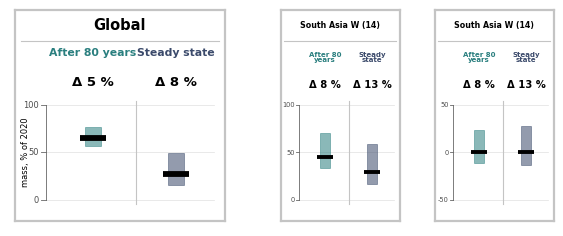

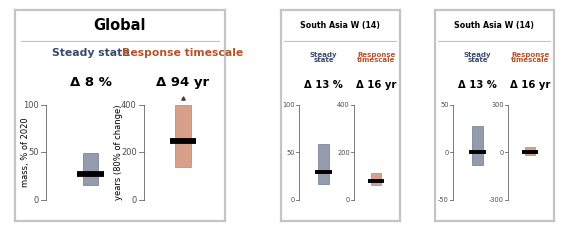

In [18]:
# test: the Global subplot and one region, as for the pies in the GMIP3-comm notebook
for variant in ['y80', 'tau']:
    fig = plt.figure(figsize=(7, 2.2))
    ax = fig.add_axes([0.02, 0.02, 0.3, 0.96])
    reg_subplot(reg='All', ax=ax, variant=variant, mode='abs', title='Global', big=True)
    ax = fig.add_axes([0.40, 0.02, 0.17, 0.96])
    reg_subplot(reg='14', ax=ax, variant=variant, mode='abs', title='South Asia W\u00a0(14)')
    ax = fig.add_axes([0.62, 0.02, 0.17, 0.96])
    reg_subplot(reg='14', ax=ax, variant=variant, mode='diff', title='South Asia W\u00a0(14)')
    plt.show()

## 3. Global subplot with legend

All explanations that are not part of the subplot itself are given by arrows in the legend (the definitions go to the figure caption).

In [19]:
def global_subplot_with_legend(fig, rect, variant='y80', mode='abs', style=None):
    if style is None:
        style = subplot_style
    ax_patch = fig.add_axes(rect, zorder=6)
    ax_patch.set_xlim(0, 1)
    ax_patch.set_ylim(0, 1)
    ax_patch.set_xticks([])
    ax_patch.set_yticks([])
    for sp in ax_patch.spines.values():
        sp.set_color('#1f4e5f')
        sp.set_linewidth(2.0)
    ax_patch.text(0.5, 0.965, 'Glacier model differences', fontsize=10, weight='bold', ha='center', va='center')
    ax_patch.text(0.5, 0.915, f'{n_scen} climate scenarios between {temp_bin[0]:.1f}\u00b0C\nand {temp_bin[1]:.1f}\u00b0C global warming',
                  fontsize=6.6, ha='center', va='center', linespacing=1.1)

    x0, y0, w, h = rect
    ax_glob = fig.add_axes([x0 + 0.03 * w, y0 + 0.46 * h, 0.94 * w, 0.40 * h], zorder=7)
    reg_subplot(reg='All', ax=ax_glob, variant=variant, mode=mode, title='Global', big=True, style=style)

    arrow = dict(arrowstyle='-|>', color='k', lw=0.6, shrinkA=0, shrinkB=0)
    if style == 'range':
        # dummy subplot with arrows
        col = col_80 if variant == 'y80' else col_ss
        ax_patch.add_patch(Rectangle((0.085, 0.10), 0.05, 0.19, fc=col, ec=col, alpha=0.55, lw=0.6))
        ax_patch.plot([0.06, 0.16], [0.19, 0.19], color='k', lw=4, solid_capstyle='butt')
        ax_patch.text(0.11, 0.345, '\u0394 10 %', fontsize=8, weight='bold', ha='center', va='center')
        ax_patch.annotate('', xy=(0.18, 0.345), xytext=(0.27, 0.350), arrowprops=arrow)
        ax_patch.text(0.285, 0.350, '\u0394: median difference of the four global models\nto their median (over 31 climate scenarios between 2.0°C and 4.0°C'), fontsize=6.6, va='center')
        ax_patch.annotate('', xy=(0.145, 0.265), xytext=(0.27, 0.255), arrowprops=arrow)
        ax_patch.text(0.285, 0.250, 'from the lowest to the highest\nof the four global models', fontsize=6.6, va='center')
        ax_patch.annotate('', xy=(0.175, 0.19), xytext=(0.27, 0.15), arrowprops=arrow)
        ax_patch.text(0.285, 0.145, 'median of the four global models' + (' (= 0)' if mode == 'diff' else ''),
                      fontsize=6.6, va='center')
    else:
        ax_patch.plot([0.05, 0.14], [0.385, 0.385], color='0.15', lw=4, solid_capstyle='butt')
        ax_patch.text(0.17, 0.385, 'median of the four global models' + (' (= 0)' if mode == 'diff' else ''), fontsize=6.6, va='center')
        ax_patch.text(0.05, 0.340, 'Global models (in median)', fontsize=6.2, weight='bold', va='center')
        ax_patch.text(0.52, 0.340, 'Regional models (not in median)', fontsize=6.2, weight='bold', va='center')
        for k, m in enumerate(global_models):
            ax_patch.plot([0.07], [0.297 - 0.040 * k], 'o', ms=5.5, mfc=dict_model_col[m], mec='0.15', mew=0.5)
            ax_patch.text(0.11, 0.297 - 0.040 * k, m, fontsize=6.2, va='center')
        for k, m in enumerate(regional_models):
            ax_patch.plot([0.54], [0.297 - 0.040 * k], 'D', ms=5, mfc=dict_model_col[m], mec='0.15', mew=0.5)
            ax_patch.text(0.58, 0.297 - 0.040 * k, m, fontsize=6.2, va='center')
        ax_patch.text(0.05, 0.075, '\u0394: median model difference of the four global models', fontsize=6.6, va='center')

## 4. The worldmap

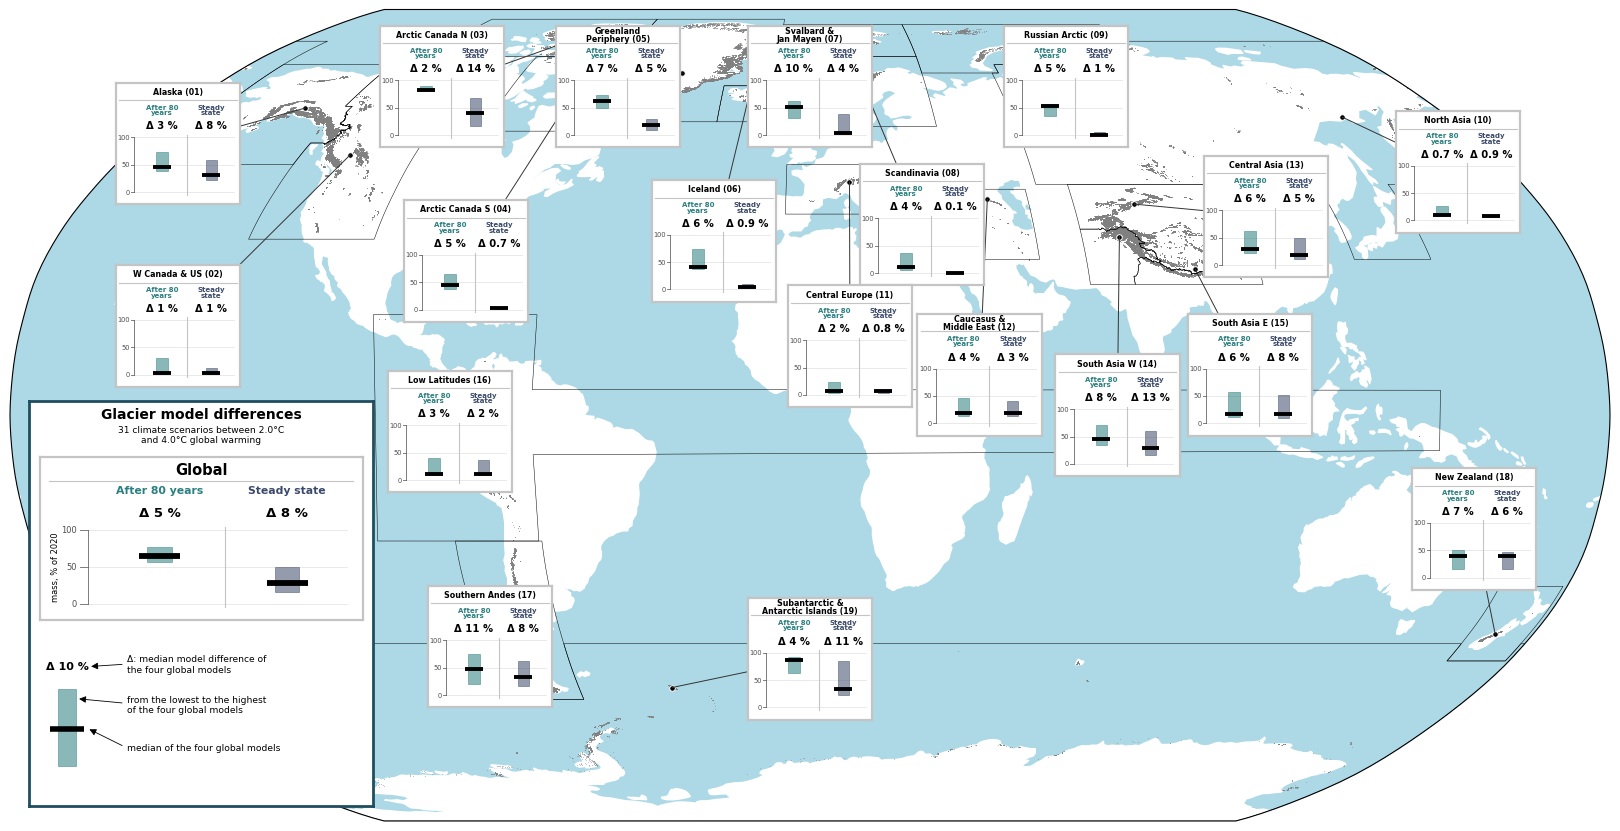

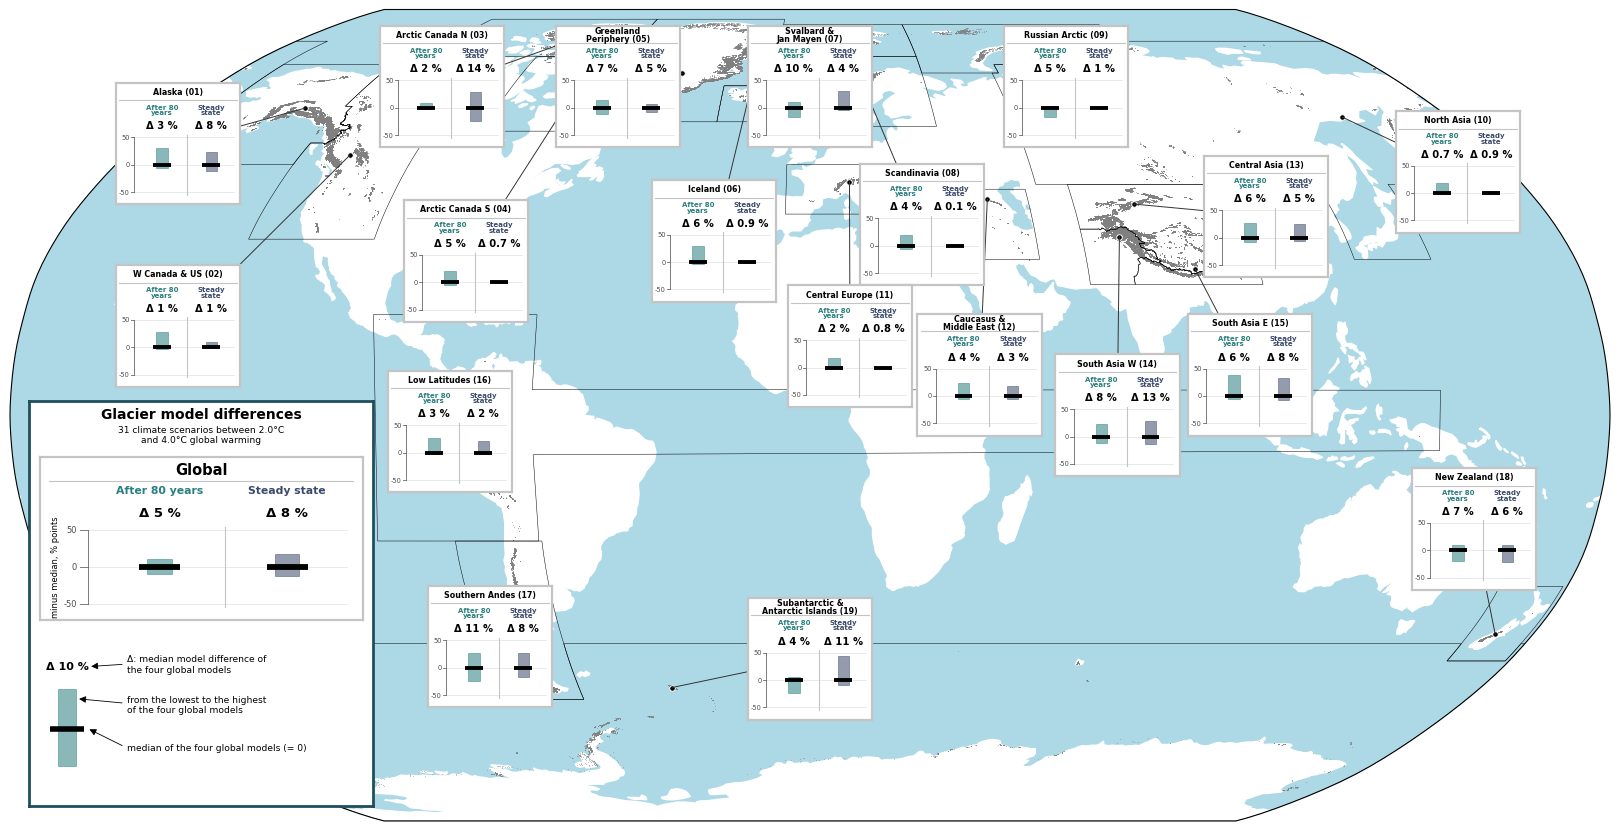

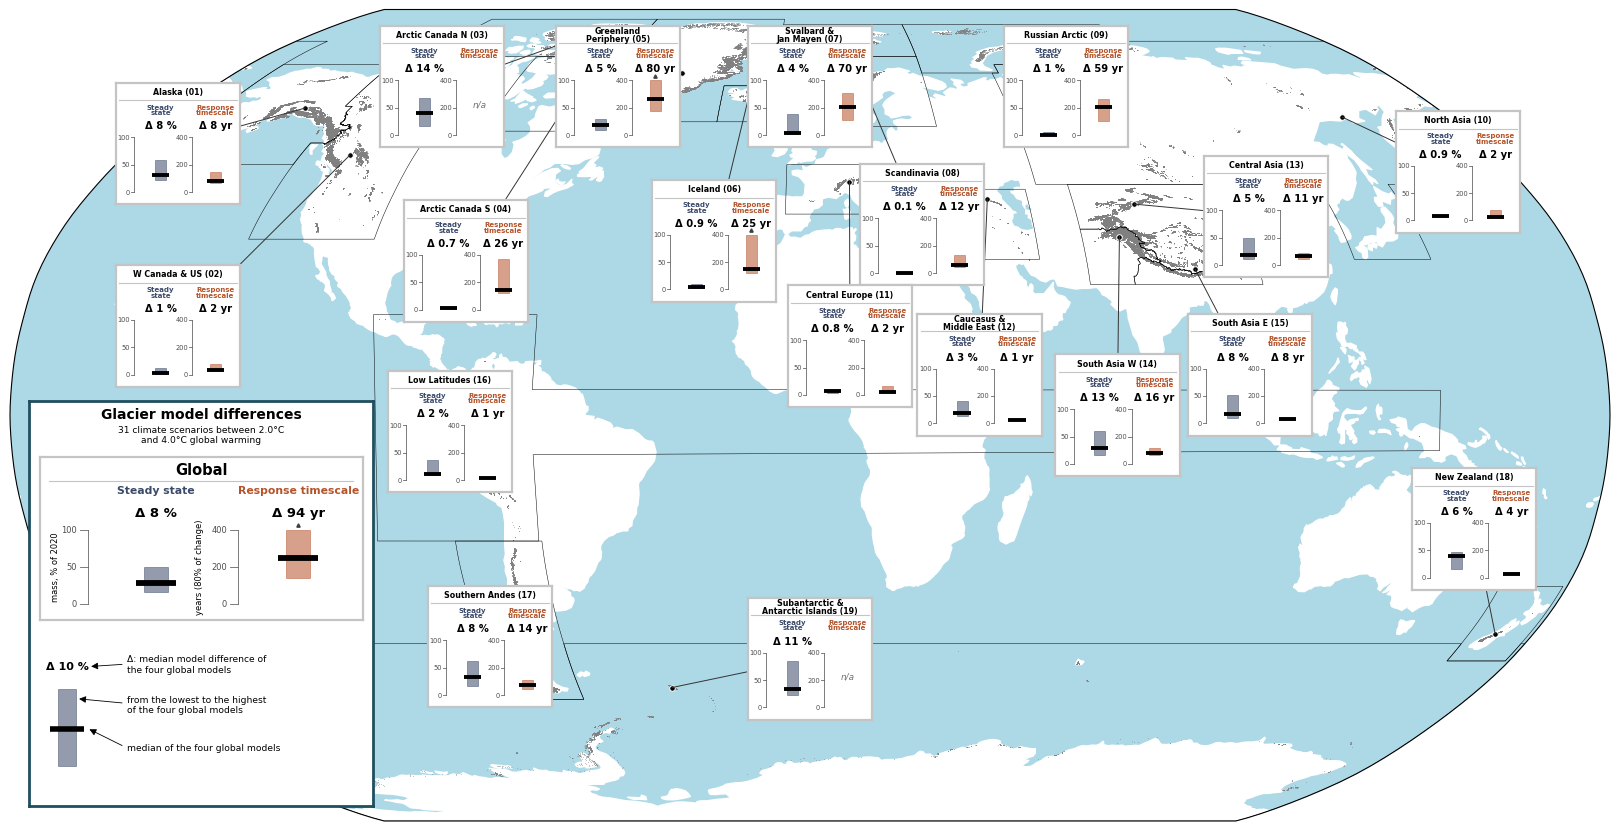

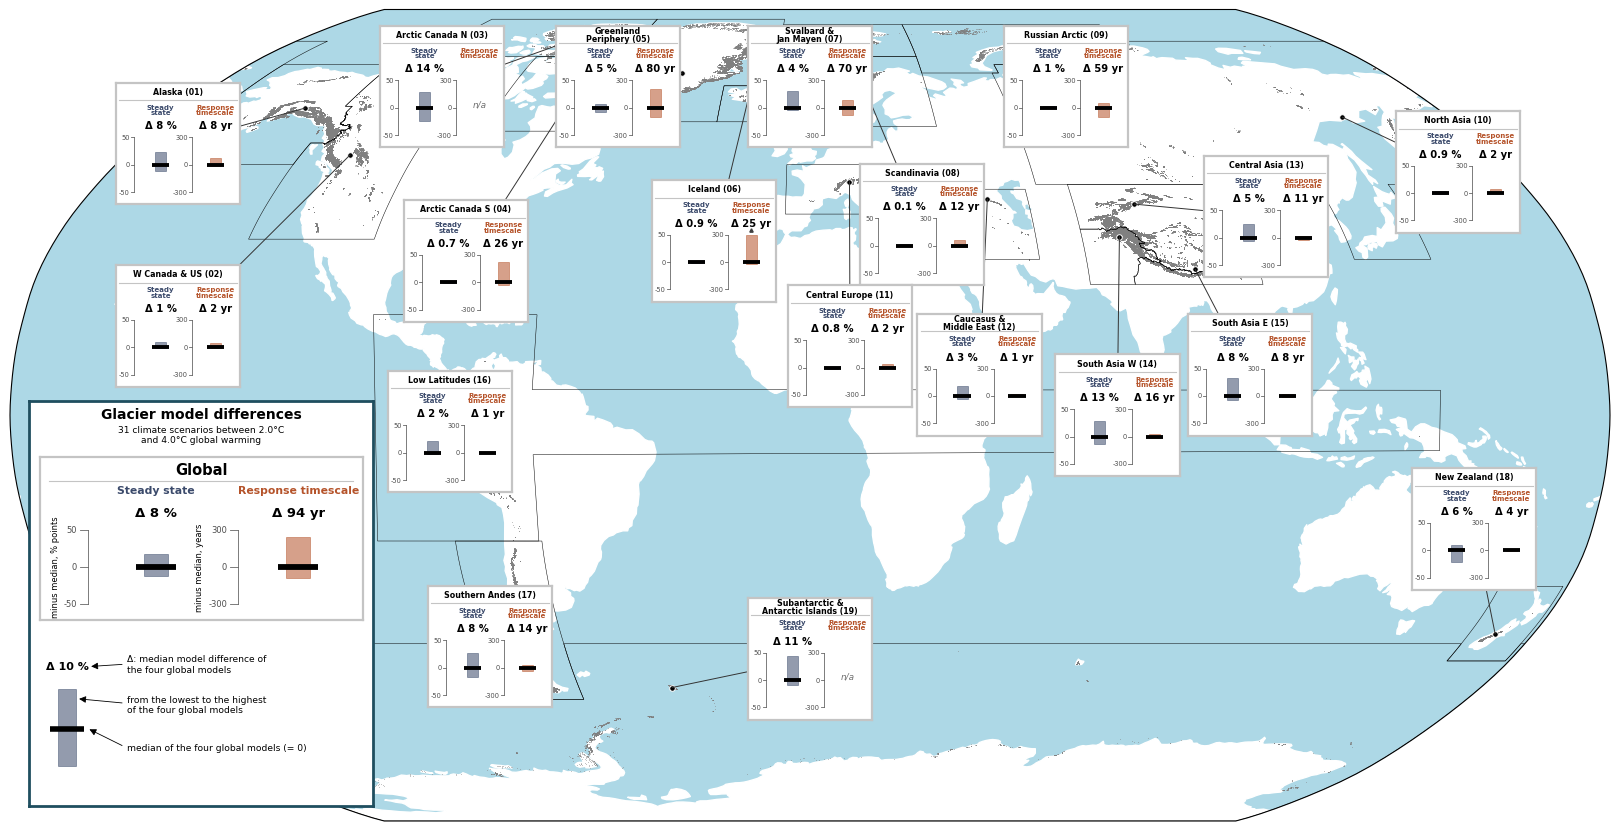

In [21]:
variant_name = {'y80': '80yr_vs_steady_state', 'tau': 'steady_state_vs_resp_time'}
mode_name = {'abs': 'absolute', 'diff': 'difference'}

for variant in variants:
    for mode in modes:
        fig = plt.figure(figsize=(16, 16 / 1.9716))

        # Add background image
        ax_background = fig.add_axes([0, 0, 1, 1], projection=ccrs.Robinson())
        ax_background.patch.set_facecolor('lightblue')
        ax_background.get_yaxis().set_visible(False)
        ax_background.get_xaxis().set_visible(False)
        ax_background.add_feature(cartopy.feature.LAND, color='white')

        # Add RGI glacier dots and RGI regions (as in the GMIP3-comm worldmap)
        if add_rgi_glaciers:
            ax_background.scatter(df_rgi6g.CenLon.values, df_rgi6g.CenLat.values,
                                  facecolor='grey', s=0.25, alpha=0.7, linewidths=0, edgecolor='grey',
                                  transform=ccrs.PlateCarree(), rasterized=False)
        if add_rgi_regions:
            shape_feature = ShapelyFeature(Reader(rgi_regions_fn).geometries(), ccrs.Robinson(), alpha=1,
                                           facecolor='None', linewidth=0.35, edgecolor='k')
            ax_background.add_feature(shape_feature)

        # Add the global subplot with the legend
        global_subplot_with_legend(fig, [0.012, 0.018, 0.215, 0.50], variant=variant, mode=mode)

        # Add the subplots of the regions
        subplot_w, subplot_h = 0.078, 0.15
        for reg in subplot_pos.keys():
            lon, lat = reg_lonlat[reg]
            x_reg, y_reg = ccrs.Robinson().transform_point(lon, lat, ccrs.PlateCarree())
            # line from the subplot to the region, behind the subplot
            fig.add_artist(ConnectionPatch(xyA=(x_reg, y_reg), coordsA=ax_background.transData, xyB=subplot_pos[reg],
                                           coordsB=fig.transFigure, color='0.2', lw=0.7, zorder=3))
            ax_background.plot(lon, lat, 'o', ms=4, mfc='k', mec='w', mew=0.7, transform=ccrs.PlateCarree(), zorder=4)

            ax = fig.add_axes([subplot_pos[reg][0] - subplot_w / 2, subplot_pos[reg][1] - subplot_h / 2, subplot_w, subplot_h], zorder=6)
            if show_numbers:
                title = f'{reg_names_lines[reg]}\u00a0({reg})'
            else:
                title = reg_names_lines[reg].replace('\n', ' ')
            reg_subplot(reg=reg, ax=ax, variant=variant, mode=mode, title=title)

        # plotting with a transform changes the extent of the map, so set it back to the whole globe
        ax_background.set_global()

        fn_out = f'{fig_dir}/PartB_worldmap_{variant_name[variant]}_{mode_name[mode]}_{subplot_style}'
        plt.savefig(fn_out + '.png', dpi=150)
        plt.savefig(fn_out + '.pdf')
        plt.show()

## Suggested captions (LaTeX)

```latex
% variant y80
\caption{Glacier model differences in the transient and steady-state mass response of the four global glacier models
(PyGEM-OGGM, GloGEMflow, OGGM, GLIMB) for the 19 RGI regions and globally, for global warming levels between
2.0$^\circ$C and 4.0$^\circ$C (31 climate scenarios). Left: glacier mass remaining after 80 simulation years
(mean of years 70 to 89), right: at steady state (mean of the last 100 simulation years), both as percentage of the
2020 mass. The bars range from the lowest to the highest of the four global models (each model: median over the 31 climate scenarios),
the black lines show their median (per climate scenario, then median over the 31 scenarios). The number gives the median glacier model difference $\Delta$, i.e., the median of the
absolute differences between each global model and the median of the four global models over all models and climate scenarios.}

% variant tau
\caption{As Fig.~\ref{...}, but left: steady-state mass, right: response timescale (time until 80\,\% of the total mass
change has occurred, counted from the simulation start). \TODO{No estimate (n/a) where more than 25\,\% of the experiments of one of the global models do not reach the required mass change.}}
```